# Fase 1 — Análisis exploratorio de datos
**Objetivo:** predecir Frío de D+1 con información disponible al cierre de D. Hipótesis: Servicios y los equipos de refrigeración contienen información física directa; Producción, Agua, Vapor y Aire reflejan actividad operativa; KPI puede contener metas administrativas o variables redundantes.

Se inspecciona la estructura de los tres Excel completos. Los experimentos predictivos se restringen al Train histórico (fecha original y candidata hasta 12/11/2022). No se redefine aún el split ni se vuelve a evaluar Test. Las fechas reconstruidas son candidatas, no certificadas.

In [55]:
from pathlib import Path
import sys, json, zipfile
from datetime import timedelta
from collections import defaultdict
from itertools import combinations
from tempfile import TemporaryDirectory
from lxml import etree as ET
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
DATA = ROOT/'data'
sys.path.insert(0,str(ROOT/'src'))
import auxiliar_functions as af
FILES = sorted(DATA.glob('Totalizadores Planta*.xlsx'))
assert len(FILES)==3
TRAIN_FIN = af.CORTE
np.random.seed(af.SEMILLA)
sns.set_theme(style='whitegrid')

## 1. Inventario y versionado (1.1)
Unificamos las lecturas eléctricas sin alterar el orden ni los valores originales. SHA-256 tiene mayor resistencia a colisiones que MD5. El hash de la nueva serialización se guarda con una clave propia en el manifiesto histórico; el CSV se genera temporalmente.

In [56]:
manifest_path=DATA/'checksums.json'
manifest=json.loads(manifest_path.read_text(encoding='utf8')) if manifest_path.exists() else {}
hashes={f'data/{p.name}':af.huella(p) for p in FILES}
for k,v in hashes.items():
    if k in manifest: assert manifest[k]==v, f'Fuente modificada: {k}'
raw=pd.concat([af.leer_ee_original(p) for p in FILES],ignore_index=True)
with TemporaryDirectory() as tmp:
    p=Path(tmp)/'consolidado_ee_revision.csv'
    raw.to_csv(p,index=False,lineterminator='\n',encoding='utf8'); h=af.huella(p)
key='eda/consolidado_ee_revision.csv'
if key in manifest: assert manifest[key]==h,'Cambió la serialización del consolidado'
manifest.update(hashes);manifest[key]=h
manifest_path.write_text(json.dumps(manifest,indent=2)+'\n',encoding='utf8')
print('Dimensiones del consolidado EE:',raw.shape,'| SHA-256:',h)
display(raw.dtypes.astype(str).value_counts().rename('columnas'));del raw

Dimensiones del consolidado EE: (43515, 23) | SHA-256: 6caab87598b29fc96bd6cbbda10b91a2c8888c8be46b326c7c7e262d29a07470


float64    20
str         2
int64       1
Name: columnas, dtype: int64

## 2. Jornadas apiladas y solapamientos
Una jornada completa tiene 25 lecturas. Un cambio de etiqueta o un retroceso horario de al menos 12 h inicia un bloque. Los retrocesos menores se registran como anomalías internas. Asignamos fechas consecutivas desde la primera etiqueta como hipótesis y contrastamos las siete hojas.

In [57]:
bloques, inventario, esquemas = [], [], {}
for p in FILES:
    with zipfile.ZipFile(p) as z:
        ss=[''.join(s.xpath('.//*[local-name()="t"]/text()')) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))]
        rel={r.get('Id'):r.get('Target') for r in ET.fromstring(z.read('xl/_rels/workbook.xml.rels'))}
        rutas={s.get('name'):rel[s.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')] for s in ET.fromstring(z.read('xl/workbook.xml')).findall('.//{*}sheet')}
        for hoja in af.HOJAS:
            t=rutas[hoja];ruta=t.lstrip('/') if t.startswith('/') else 'xl/'+t
            with z.open(ruta) as f:
                _,row=next(ET.iterparse(f,events=('end',),tag='{*}row'))
                cols={ss[int(c.findtext('{*}v'))].strip() for c in row if c.get('t')=='s' and c.findtext('{*}v') is not None}
            esquemas[p.name,hoja]=cols
            g,retro,invalidas=af.segmentar(af.leer_temporal(z,ruta,ss));labels=[b[0][1] for b in g]
            if hoja=='Consolidado EE':ref=labels
            igual=labels==ref
            inventario.append(dict(archivo=p.name,hoja=hoja,filas=sum(map(len,g)),columnas=len(cols),bloques=len(g),alineada=igual,retrocesos=len(retro),invalidas=invalidas))
            for j,b in enumerate(g):
                bloques.append(dict(archivo=p.name,hoja=hoja,bloque=j+1,fecha_original=b[0][1],fecha_candidata=labels[0]+timedelta(days=j),fila_inicio=b[0][0],fila_fin=b[-1][0],n_filas=len(b),completo=len(b)==25 and {r[2] for r in b}==af.ESPERADAS,secuencia_igual_EE=igual))
mapa=pd.DataFrame(bloques);mapa[['fecha_original','fecha_candidata']]=mapa[['fecha_original','fecha_candidata']].apply(pd.to_datetime)
inv=pd.DataFrame(inventario);assert inv.alineada.all()
display(inv.pivot(index='archivo',columns='hoja',values='bloques'))
display(inv.groupby('hoja').agg(filas_totales=('filas','sum'),columnas_min=('columnas','min'),columnas_max=('columnas','max')))
print('Hojas alineadas:',inv.alineada.sum(),'| retrocesos internos:',inv.retrocesos.sum())
ee=mapa.query("hoja == 'Consolidado EE'")
for a,g in ee.groupby('archivo'):
    n=g.fecha_original.nunique();dias=(g.fecha_original.max()-g.fecha_original.min()).days+1
    print(a,'| bloques:',len(g),'| extras:',len(g)-n,'| fechas ausentes:',dias-n)
display(pd.DataFrame([(h,len(set.intersection(*(esquemas[p.name,h] for p in FILES))),len(set.union(*(esquemas[p.name,h] for p in FILES)))) for h in af.HOJAS],columns=['hoja','comunes','union']))

hoja,Consolidado Agua,Consolidado Aire,Consolidado EE,Consolidado GasVapor,Consolidado KPI,Consolidado Produccion,Totalizadores Energia
archivo,,,,,,,
Totalizadores Planta - 2021_2023.xlsx,614,614,614,614,614,614,614
Totalizadores Planta 2020_2022.xlsx,624,624,624,624,624,624,624
Totalizadores Planta 2022_2023.xlsx,482,482,482,482,482,482,482


,filas_totales,columnas_min,columnas_max
hoja,,,
Consolidado Agua,42852,18,24
Consolidado Aire,42900,14,14
Consolidado EE,42900,21,21
Consolidado GasVapor,42900,17,20
Consolidado KPI,42898,62,125
Consolidado Produccion,42898,12,18
Totalizadores Energia,42900,53,59


Hojas alineadas: 21 | retrocesos internos: 4
Totalizadores Planta - 2021_2023.xlsx | bloques: 614 | extras: 12 | fechas ausentes: 12
Totalizadores Planta 2020_2022.xlsx | bloques: 624 | extras: 12 | fechas ausentes: 12
Totalizadores Planta 2022_2023.xlsx | bloques: 482 | extras: 8 | fechas ausentes: 9


,hoja,comunes,union
0,Consolidado EE,21,21
1,Consolidado Produccion,12,18
2,Totalizadores Energia,53,60
3,Consolidado Agua,18,24
4,Consolidado GasVapor,16,21
5,Consolidado Aire,14,14
6,Consolidado KPI,61,126


In [58]:
ciclos=[]
for a,g in ee.groupby('archivo'):
    for anio in range(2020,2024):
        ini=pd.Timestamp(anio,7,1);fin=pd.Timestamp(anio+1,7,1)
        if g.fecha_original.eq(ini).any() and g.fecha_original.eq(fin).any():
            ciclos.append(g.loc[g.fecha_original.between(ini,fin,inclusive='left'),'fecha_original'].dt.strftime('%m-%d').tolist())
print('Ciclos completos:',len(ciclos),'| bloques:',[len(c) for c in ciclos],'| secuencias iguales:',all(c==ciclos[0] for c in ciclos))
ultimo=ee.groupby('archivo').fecha_original.max().idxmax();g=ee[ee.archivo.eq(ultimo)]
for anio in (2022,2023):
    s=g.loc[g.fecha_original.between(pd.Timestamp(anio,7,1),pd.Timestamp(anio,10,26)),'fecha_original']
    print(f'Jul–oct {anio}: {len(s)} bloques')

Ciclos completos: 3 | bloques: [365, 365, 365] | secuencias iguales: True
Jul–oct 2022: 116 bloques
Jul–oct 2023: 117 bloques


Las secuencias anuales repetidas y los bloques adicionales respaldan la hipótesis de calendario consecutivo. El último archivo presenta una excepción en agosto de 2023: no podemos certificar las fechas absolutas. Contrastamos los cierres y desfases exclusivamente en Train.

In [59]:
dias=defaultdict(list); fichas=[]
for p in FILES:
    for a,j,orig,cand,rows in af.leer_archivo(p):
        d,s=af.clasificar(rows);f=dict(archivo=a,bloque=j,fecha_original=orig,fecha_candidata=cand,**s)
        fichas.append(f);dias[cand].append((f,d))
q=pd.DataFrame(fichas);q[['fecha_original','fecha_candidata']]=q[['fecha_original','fecha_candidata']].apply(pd.to_datetime)
assert q[['fecha_original','fecha_candidata']].max().max()<=TRAIN_FIN
sol=[]
for fecha,gr in dias.items():
    for (a,_),(b,_) in combinations(gr,2):
        if a['cierre'] is not None and b['cierre'] is not None:sol.append((fecha,a['cierre']==b['cierre']))
sol=pd.DataFrame(sol,columns=['fecha','igual']);print('Fechas solapadas:',sol.fecha.nunique(),'| cierres iguales:',sol.igual.sum(),'/',len(sol))
v=q[q.valido_completo].pivot(index='fecha_candidata',columns='archivo',values='cierre');desf=[]
for a,b in combinations(v.columns,2):
    x,y=v[a].dropna(),v[b].dropna();ds=[d for d in x.index if all(d+pd.Timedelta(days=k) in y.index for k in range(-3,4))]
    for k in range(-3,4):desf.append((k,len(ds),sum(x[d]==y[d+pd.Timedelta(days=k)] for d in ds)))
display(pd.DataFrame(desf,columns=['desfase','pares','iguales']).groupby('desfase').sum())

Fechas solapadas: 388 | cierres iguales: 383 / 388


,pares,iguales
desfase,,
-3,253,0
-2,253,0
-1,253,0
0,253,252
1,253,0
2,253,0
3,253,0


## 3. Calidad de los totalizadores
El cierre a las 23:59 es el consumo de la jornada. Exigimos 25 horarios únicos, reinicio a cero, lecturas finitas no negativas y monotonía. Excluimos referencias con cierres contradictorios o perfiles válidos diferentes; entre referencias coherentes preferimos la extracción más reciente. No se imputan targets.

In [60]:
display(pd.Series({'bloques fuente':len(q),'fechas candidatas':len(dias),'incompletos':(~q.completo).sum(),'inicio no cero':q.inicio.ne(0).sum(),'descensos':q.descensos.gt(0).sum(),'cierres > 1 millón':q.cierre.gt(1e6).sum(),'completos plausibles':q.valido_completo.sum()}))
refs=[];conflictos=[];H={};horas=af.HORAS
for fecha,gr in sorted(dias.items()):
    buenos=[(f,d) for f,d in gr if f['valido_completo']]
    if len({f['cierre'] for f,d in gr if f['cierre'] is not None})>1:
        conflictos.append((fecha,buenos));continue
    if not buenos or any(d!=buenos[0][1] for f,d in buenos):continue
    f,d=buenos[0];H[pd.Timestamp(fecha)]=[d[h] for h in horas];refs.append({'fecha_candidata':pd.Timestamp(fecha),'real':d[af.CIERRE]})
refs=pd.DataFrame(refs);perfil=pd.DataFrame.from_dict(H,orient='index',columns=horas).sort_index()
print('Referencias plausibles:',len(refs),'| fechas con cierres discrepantes:',len(conflictos))
# Ocultar el cierre observado y comparar extrapolaciones.
pred={'23:00':perfil[af.H23]}
for k in (1,3,6):pred[f'ritmo {k}h']=perfil[af.H23]+(perfil[af.H23]-perfil[af.H23-k*3600])/k*59/60
err=pd.DataFrame(pred).sub(perfil[af.CIERRE],axis=0)
display(pd.DataFrame({'MAE':err.abs().mean(),'RMSE':np.sqrt(err.pow(2).mean()),'sesgo':err.mean()}).round(2))

bloques fuente          1253
fechas candidatas        862
incompletos               37
inicio no cero             4
descensos                 32
cierres > 1 millón         5
completos plausibles    1183
dtype: int64

Referencias plausibles: 812 | fechas con cierres discrepantes: 5


,MAE,RMSE,sesgo
23:00,1016.12,1148.49,-1016.12
ritmo 1h,209.53,447.48,-6.03
ritmo 3h,197.57,523.48,31.64
ritmo 6h,193.80,456.41,38.54


### Saltos y reinicios
Calibramos el detector con el primer 70% de referencias y simulamos cinco errores en cuatro horarios del 30% posterior. Umbral heurístico: máximo entre 3×P99 de los ritmos históricos y 6×mediana absoluta del ritmo diario.

Calibración / comprobación: 568 244 | P99: 1951.38 | referencias con alertas: 8


,n,deteccion,MAE_original,MAE_reparado
error,,,,
10000,976,0.988,10000.000,289.864
2870000,976,0.989,2870000.000,32513.612
32768,976,0.989,32768.000,536.612
5000,976,0.182,5000.000,4118.583
reinicio,976,0.734,15940.213,1895.786


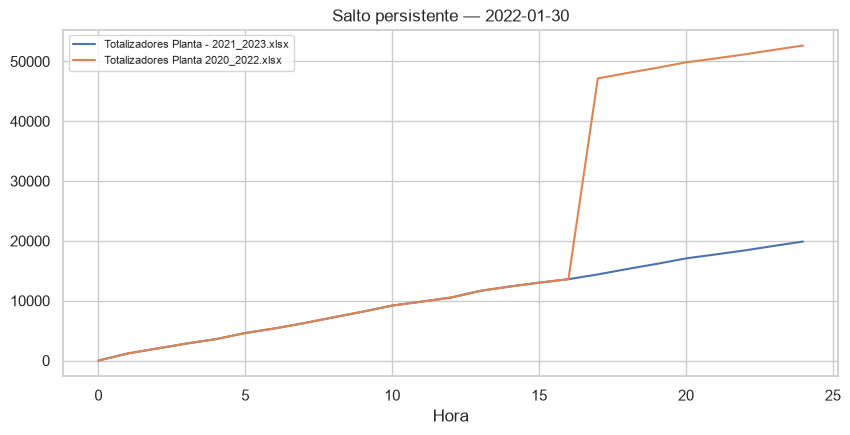

In [61]:
cal=perfil.iloc[:int(.7*len(perfil))];ver=perfil.iloc[len(cal):]
p99=np.quantile((np.diff(cal,axis=1)/np.array(af.DUR)).ravel(),.99);piso=3*p99
alerta=perfil.apply(lambda v:len(af.detectar(v.tolist(),piso)[0]),axis=1)
print('Calibración / comprobación:',len(cal),len(ver),'| P99:',round(p99,2),'| referencias con alertas:',alerta.gt(0).sum())
sim=[]
for v in ver.to_numpy():
    for j in (6,12,17,24):
        for tipo in (5000,10000,32768,2870000,'reinicio'):
            cor=v.copy();cor[j:]+= -v[j] if tipo=='reinicio' else tipo
            hit,_=af.detectar(cor.tolist(),piso);est=af.reparar(cor.tolist(),hit[0],'mediana_local')[-1] if len(hit)==1 else cor[-1]
            sim.append((str(tipo),hit==[j],abs(cor[-1]-v[-1]),abs(est-v[-1])))
sim=pd.DataFrame(sim,columns=['error','deteccion_exacta','error_original','error_reparado'])
display(sim.groupby('error').agg(n=('error','size'),deteccion=('deteccion_exacta','mean'),MAE_original=('error_original','mean'),MAE_reparado=('error_reparado','mean')).round(3))
for fecha,buenos in conflictos:
    if len(buenos)!=2:continue
    (f1,d1),(f2,d2)=sorted(buenos,key=lambda fd:fd[1][af.CIERRE]);v1,v2=[np.array([d[h] for h in horas]) for d in (d1,d2)]
    if np.isclose(v2[-1]-v1[-1],32768):
        plt.plot(np.array(horas)/3600,v1,label=f1['archivo']);plt.plot(np.array(horas)/3600,v2,label=f2['archivo']);plt.title(f'Salto persistente — {fecha}');plt.xlabel('Hora');plt.legend(fontsize=8);plt.show();break

La extrapolación de seis horas reduce el MAE frente a usar 23:00. El detector identifica bien saltos grandes, pero no todos los moderados ni los reinicios. Se utiliza como alerta; se prioriza una fuente observada coherente. Las estimaciones son candidatas exclusivamente para predictores.

## 4. Valores faltantes
Integramos las siete hojas en las referencias, distinguiendo columnas inexistentes, bloques incompletos y celdas vacías. Comprobamos los alias de Vapor L5 antes de unificarlos.

Leídos cierres de referencia: Totalizadores Planta - 2021_2023.xlsx
Leídos cierres de referencia: Totalizadores Planta 2020_2022.xlsx
Leídos cierres de referencia: Totalizadores Planta 2022_2023.xlsx


,celdas
estado,
sin_columna,5310
vacio,293
bloque_incompleto,50


Alias Vapor L5: 230 pares | coincidencias: 230


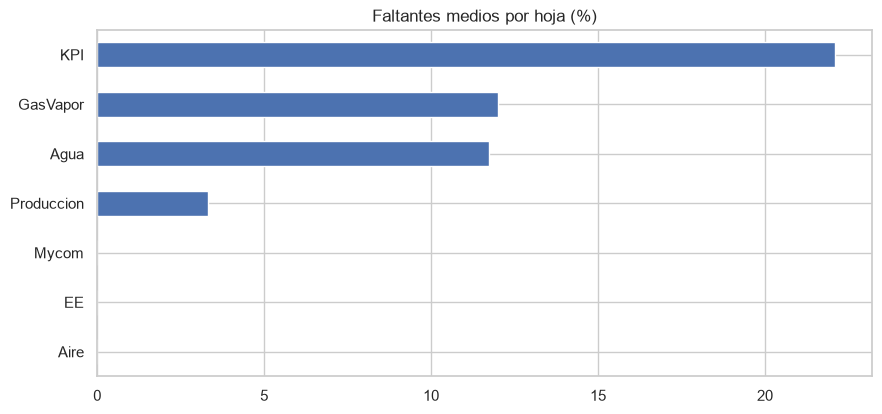

GasVapor | Vapor _Vapor_L5 (KG)    57.389163
Agua | Agua Calderas               42.733990
Agua | Agua CO2                    42.733990
Agua | Agua Efluentes              42.733990
Agua | Agua Paste L3               42.733990
Agua | Agua Lavadora L3            42.733990
Agua | Agua Cond Evaporativos      42.733990
KPI | Meta Aire Planta             42.610837
GasVapor | Vapor_L5 (KG)           42.610837
KPI | Meta ET Planta               42.610837
Name: % faltante, dtype: float64

In [62]:
X,estados,alias=af.extraer(DATA,mapa,refs,q)
display(estados[estados.estado.ne('observado')].estado.value_counts().to_frame('celdas'))
print('Alias Vapor L5:',len(alias),'pares | coincidencias:',np.isclose(alias.diferencia,0,atol=1e-6,rtol=0).sum())
na=X.drop(columns=['archivo','frio_observado']).isna().mean()
na.groupby(na.index.str.split(' | ',regex=False).str[0]).mean().sort_values().mul(100).plot.barh(title='Faltantes medios por hoja (%)');plt.show()
display(na.sort_values(ascending=False).head(10).mul(100).rename('% faltante'))

### Imputación
Ocultamos valores aislados y bloques de siete días (cinco repeticiones, semilla 42). Se comparan mediana global, último valor, medianas históricas de 7/30 días y KNN; los parámetros se ajustan con la primera partición y el error se mide en la posterior.

Calibración: 568 | comprobación: 244 | variables: 81


,escenario,metodo,variables,mediana_ratio_vs_mediana,mediana_MAE_normalizado
0,aislado,knn_5,80,0.6941,0.4621
1,aislado,mediana_calibracion,80,1.0000,0.6035
2,aislado,mediana_previa_30d,80,0.8214,0.4686
3,aislado,mediana_previa_7d,80,0.8727,0.4763
4,aislado,ultimo_7d,80,0.8527,0.4925
5,bloques_7d,knn_5,80,0.6768,0.4488
6,bloques_7d,mediana_calibracion,80,1.0000,0.6039
7,bloques_7d,mediana_previa_30d,80,0.8455,0.4812
8,bloques_7d,mediana_previa_7d,80,0.9047,0.5106
9,bloques_7d,ultimo_7d,80,1.0327,0.5918


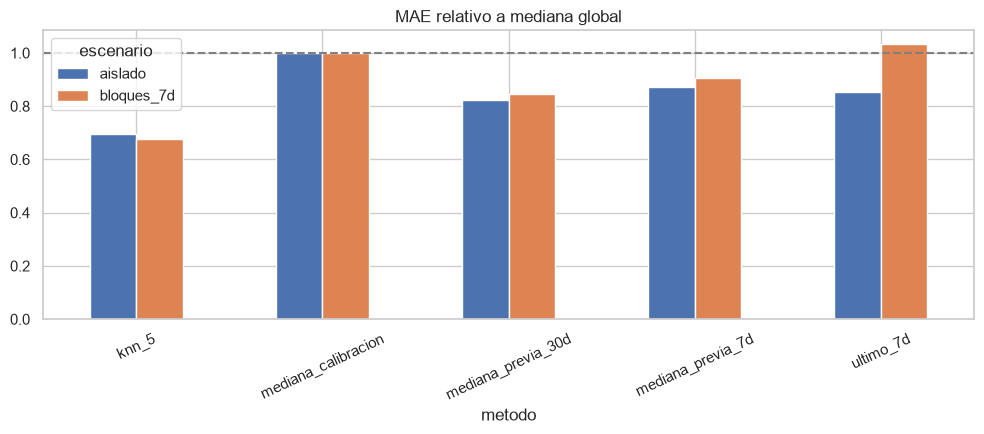

In [63]:
_,_,imp,ncal,nchk,ncols=af.simular(X)
print('Calibración:',ncal,'| comprobación:',nchk,'| variables:',ncols)
display(imp.round(4))
imp.pivot(index='metodo',columns='escenario',values='mediana_ratio_vs_mediana').plot.bar(rot=25,title='MAE relativo a mediana global');plt.axhline(1,color='gray',ls='--');plt.tight_layout();plt.show()

La mayoría de faltantes es estructural. KNN mejora la reconstrucción artificial, pero no garantiza menor error predictivo ni permite recuperar sensores nunca observados. La elección se hará en validación temporal.

## 5. Serie diaria y distribución
Unificamos el alias Vapor L5 e incorporamos medidores eléctricos adicionales y ventanas de 3, 6 y 12 h. Excluimos referencias con alertas. Se reindexa el calendario completo antes de desplazar el objetivo: un día ausente no puede convertir D+2 en D+1.

Referencias: 804 | pares D/D+1: 752 | extremos enmascarados: 44


,Frío D,Frío D+1
count,804.00,752.00
mean,24614.20,24525.67
std,7863.81,7773.19
min,2310.00,2310.00
25%,19034.50,19175.00
50%,25490.00,25520.50
75%,30479.50,30400.75
max,48046.00,48046.00


,count,min,max,mean,std,faltantes,unicos,tipo
GasVapor | Tot Vap Lav L3 / Hora,457.0,0.00,6962.67,2041.81,1344.94,347,415,float64
Agua | Agua Paste L3,458.0,-0.42,290.07,3.09,14.80,346,144,float64
Agua | Agua Cond Evaporativos,459.0,600.00,3441.00,1988.88,533.78,345,397,float64
Agua | Agua Lavadora L3,459.0,0.00,559.62,14.41,28.91,345,314,float64
Agua | Agua Efluentes,459.0,0.60,285.50,136.33,55.31,345,389,float64
Agua | Agua CO2,459.0,16.40,288.00,96.43,45.07,345,394,float64
KPI | Meta EE Planta,459.0,6.30,8.69,7.18,0.80,345,13,float64
KPI | Meta Agua Planta,459.0,3.30,4.17,3.48,0.22,345,7,float64
GasVapor | Tot Vap Paste L3 / Hora,459.0,-957112.50,510.00,-3657.02,56871.43,345,139,float64
GasVapor | Medicion Gas Planta (M3),459.0,1084.38,23366.19,15201.55,3786.46,345,459,float64


Constantes: ['Energia | KW Linea 4', 'Energia | Kw llum/Serv L2']


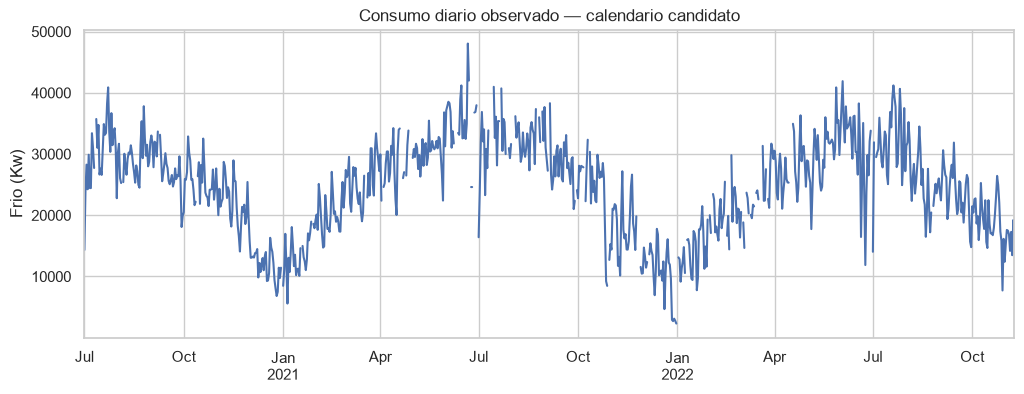

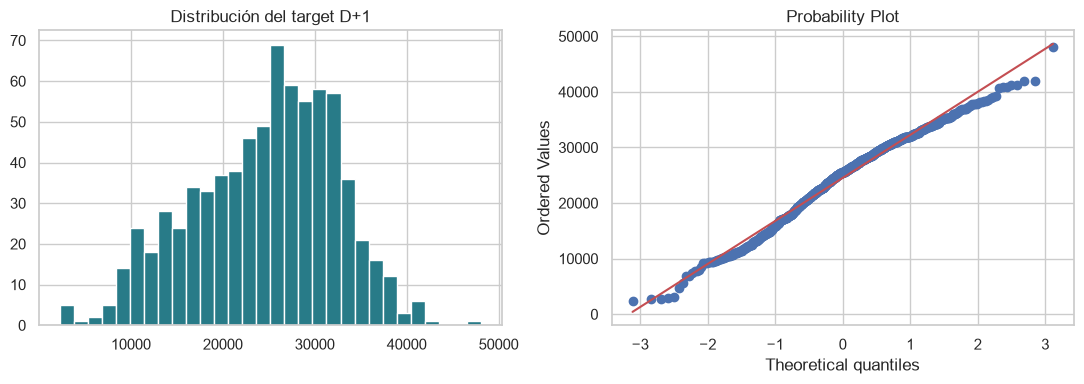

In [64]:
E={};O={}
for p in FILES:
    ds=X.index[X.archivo.eq(p.name)]
    sub=mapa[mapa.archivo.eq(p.name)&mapa.fecha_candidata.isin(ds)&mapa.hoja.eq('Totalizadores Energia')]
    E.update(af.energia(p,sub))
    O.update(q[q.archivo.eq(p.name)&q.fecha_candidata.isin(ds)].set_index('fecha_candidata').fecha_original.to_dict())
E=pd.DataFrame.from_dict(E,orient='index').reindex(X.index)
for i in range(1,8):
    c=f'KW Mycom {i}';a,b=X[f'Mycom | {c}'],E[f'Energia | {c}'];ok=a.notna()&b.notna()
    assert np.allclose(a[ok],b[ok],rtol=0,atol=1e-6);E=E.drop(columns=f'Energia | {c}')
X=X.join(E)
for k in (3,6,12):X[f'frio_ultimas_{k}h']=perfil[af.CIERRE]-perfil[(24-k)*3600]
old='GasVapor | Vapor _Vapor_L5 (KG)';new='GasVapor | Vapor_L5 (KG)'
assert np.isclose(alias.diferencia,0,rtol=0,atol=1e-6).all()
X[new]=X[new].combine_first(X[old]);X=X.drop(columns=[old,'archivo']).loc[alerta.eq(0)]
y=X.frio_observado;idx=y.index;serie=y.reindex(pd.date_range(idx.min(),idx.max()));target=serie.shift(-1).reindex(idx)
P=X.drop(columns='frio_observado');lim=10*P.quantile(.99);Q=P.mask(P.gt(lim.where(lim>0,np.inf)));Q['frio_D']=y
print('Referencias:',len(X),'| pares D/D+1:',target.notna().sum(),'| extremos enmascarados:',(P.notna()&Q[P.columns].isna()).sum().sum())
display(pd.concat([y.rename('Frío D'),target.rename('Frío D+1')],axis=1).describe().round(2))
desc=Q.agg(['count','min','max','mean','std']).T.assign(faltantes=Q.isna().sum(),unicos=Q.nunique(),tipo=Q.dtypes.astype(str))
display(desc.sort_values('faltantes',ascending=False).head(15).round(2));print('Constantes:',desc.index[desc.unicos<=1].tolist())
serie.plot(figsize=(12,4),title='Consumo diario observado — calendario candidato');plt.ylabel('Frio (Kw)');plt.show()
fig,ax=plt.subplots(1,2,figsize=(11,4));ax[0].hist(target.dropna(),bins=30,color='#287b88',edgecolor='white');ax[0].set_title('Distribución del target D+1');stats.probplot(target.dropna(),dist='norm',plot=ax[1]);plt.tight_layout();plt.show()

## 6. Estacionalidad y perfil horario
Medimos variación mensual e interanual, perfil intradiario y efecto semanal. El residuo respecto de la media de cada año-mes es exclusivamente descriptivo; no se usa como predictor porque contiene información posterior a D.

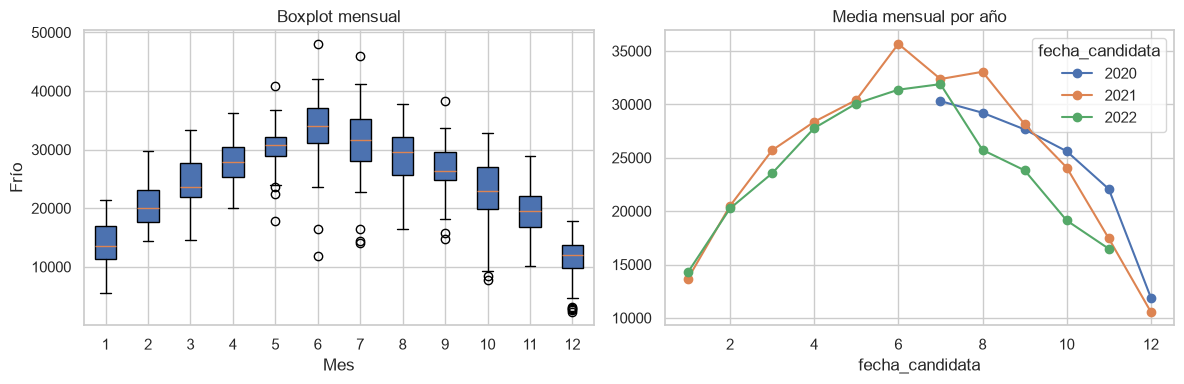

Cambio entre los mismos 10 meses: -8.86 %


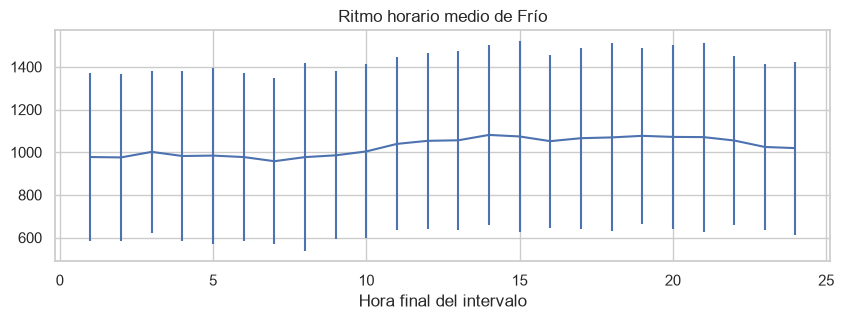

C:\Users\maxim\AppData\Local\Temp\ipykernel_35076\1494265082.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  for nombre,g in [('rotulada',pd.Series(O).reindex(idx).dt.dayofweek),('candidata',pd.Series(idx.dayofweek,index=idx))]:
C:\Users\maxim\AppData\Local\Temp\ipykernel_35076\1494265082.py:8: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  for nombre,g in [('rotulada',pd.Series(O).reindex(idx).dt.dayofweek),('candidata',pd.Series(idx.dayofweek,index=idx))]:


,calendario,serie,R2
0,rotulada,nivel,0.59
1,rotulada,sin nivel mensual,1.99
2,candidata,nivel,1.38
3,candidata,sin nivel mensual,4.82


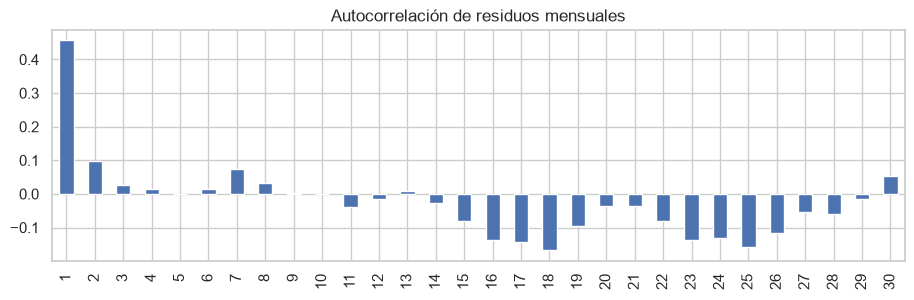

In [65]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].boxplot([y[idx.month==m].to_numpy() for m in range(1,13)],tick_labels=range(1,13),patch_artist=True);ax[0].set(xlabel='Mes',ylabel='Frío',title='Boxplot mensual')
mm=y.groupby([idx.year,idx.month]).mean().unstack(0);mm.plot(marker='o',ax=ax[1],title='Media mensual por año');plt.tight_layout();plt.show()
comunes=mm.loc[1:10,[2021,2022]].mean();print('Cambio entre los mismos 10 meses:',round((comunes[2022]/comunes[2021]-1)*100,2),'%')
ritmos=pd.DataFrame(np.diff(perfil.loc[idx],axis=1)/np.array(af.DUR),columns=np.array(horas[1:])/3600)
ritmos.mean().plot(yerr=ritmos.std(),figsize=(10,3),title='Ritmo horario medio de Frío');plt.xlabel('Hora final del intervalo');plt.show()
res=y-y.groupby(idx.to_period('M')).transform('mean');sem=[]
for nombre,g in [('rotulada',pd.Series(O).reindex(idx).dt.dayofweek),('candidata',pd.Series(idx.dayofweek,index=idx))]:
    for nivel,v in [('nivel',y),('sin nivel mensual',res)]:
        pred=v.groupby(g).transform('mean');r2=1-((v-pred)**2).sum()/((v-v.mean())**2).sum();sem.append((nombre,nivel,r2))
display(pd.DataFrame(sem,columns=['calendario','serie','R2']).assign(R2=lambda d:100*d.R2).round(2))
res_cal=res.reindex(serie.index);acf=pd.Series({k:res_cal.corr(res_cal.shift(k)) for k in range(1,31)})
acf.plot.bar(figsize=(11,3),title='Autocorrelación de residuos mensuales');plt.show()

La señal semanal aumenta con el calendario candidato y al descontar el nivel mensual, pero sigue siendo débil; evaluaremos calendario y lag 7 sin asumir su utilidad. El cambio interanual motiva medias móviles causales de 14 y 30 días.

## 7. Composición física y consumo por área
Contrastamos la suma de siete Mycom, tres grupos de condensadores y dos bombas de glicol. Los medidores están anidados: sus porcentajes respecto de Planta no constituyen necesariamente partes disjuntas.

,medidores,n,exactas,MAE,max_error,Pearson
0,7,804,0,6489.410448,10543.0,0.991145
1,10,804,0,3733.221393,5893.0,0.994266
2,12,804,630,5.191542,91.0,0.999999


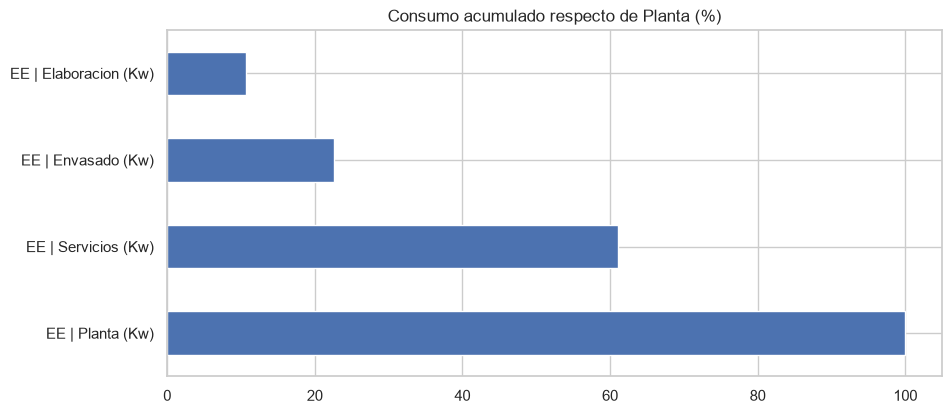

In [66]:
comp=[f'Mycom | KW Mycom {i}' for i in range(1,8)]+['Energia | KW Cond 5. 6 y 9','Energia | KW Cond 7. 8 y 11','Energia | KW Cond 11. 12 y 13','Energia | KW Bba Glicol Sala MAq','Energia | KW Bba Glicol Bod']
bal=[]
for n in (7,10,12):
    s=X[comp[:n]].sum(axis=1,min_count=n);e=(s-y).dropna();bal.append((n,len(e),np.isclose(e,0,rtol=0,atol=1e-6).sum(),e.abs().mean(),e.abs().max(),s.corr(y)))
display(pd.DataFrame(bal,columns=['medidores','n','exactas','MAE','max_error','Pearson']).round(6))
areas=['EE | '+a+' (Kw)' for a in ('Planta','Servicios','Envasado','Elaboracion')];share={}
for c in areas:
    ok=Q[c].notna()&Q[areas[0]].gt(0);share[c]=Q.loc[ok,c].sum()/Q.loc[ok,areas[0]].sum()
pd.Series(share).mul(100).plot.barh(title='Consumo acumulado respecto de Planta (%)');plt.show()

La suma de los doce medidores reproduce Frío casi exactamente; pequeñas diferencias impiden afirmar una identidad universal. La suma es redundante si conocemos Frío de D. Los componentes individuales pueden aportar información adicional.

## 8. Correlaciones y multicolinealidad
Separamos la correlación con Frío de D y D+1. Pearson mide asociación lineal; Spearman, monótona. El enmascaramiento exploratorio de valores mayores a 10×P99 positivo es una heurística, no una regla definitiva. Exigimos al menos 30 pares observados.

Correlaciones individuales |Pearson| > .98 con Frío D: 0


,analisis,variable,n,pearson,spearman
139,D+1,frio_D,752,0.8574,0.8453
138,D+1,frio_ultimas_12h,752,0.8550,0.8433
137,D+1,frio_ultimas_6h,752,0.8386,0.8313
50,D+1,EE | Servicios (Kw),752,0.8200,0.8182
136,D+1,frio_ultimas_3h,752,0.8196,0.8156
49,D+1,EE | Sala Maq (Kw),750,0.8006,0.8304
94,D+1,Energia | KW Gral Planta,751,0.7703,0.7856
44,D+1,EE | Planta (Kw),751,0.7664,0.7802
98,D+1,Energia | KW Trafo 11,752,0.7188,0.6991
76,D+1,KPI | Meta ET Planta,424,-0.7163,-0.6962


,crudo,depurado,Spearman
variable,,,
Agua | Agua Envasado (Hl),0.5635,0.5635,0.5703
Aire | Aire Envasado (M3),0.4609,0.4609,0.4625
GasVapor | Vapor Envasado (Kg),0.4120,0.4120,0.4020
GasVapor | ET Envasado (Mj),0.2962,0.2962,0.2891
EE | Envasado (Kw),-0.0113,0.5704,0.5770
EE | Sala Maq (Kw),0.0014,0.9175,0.9869


Pares redundantes: 28


,variable 1,variable 2,Pearson
21,KPI | Meta Aire Planta,KPI | Meta EE Planta,1.000000
16,GasVapor | Tot_Vapor_CIP_Bodega,GasVapor | Vapor Servicio (Kg),1.000000
10,EE | Linea 3 (Kw),Energia | KW Linea 3,0.999929
13,EE | Prod Agua (Kw),Energia | KW Filtr Carbon,0.999911
12,EE | Prod Agua (Kw),EE | Pta Agua / Eflu (Kw),0.999712
14,EE | Pta Agua / Eflu (Kw),Energia | KW Filtr Carbon,0.999574
11,EE | Planta (Kw),Energia | KW Gral Planta,0.999343
9,EE | Linea 2 (Kw),Energia | KW Trafo 8,0.999291
3,Aire | Aire Producido (M3),Energia | Kw Compresores Aire,0.990150
17,GasVapor | Vapor Cocina (Kg),GasVapor | Vapor Elaboracion (Kg),0.988743


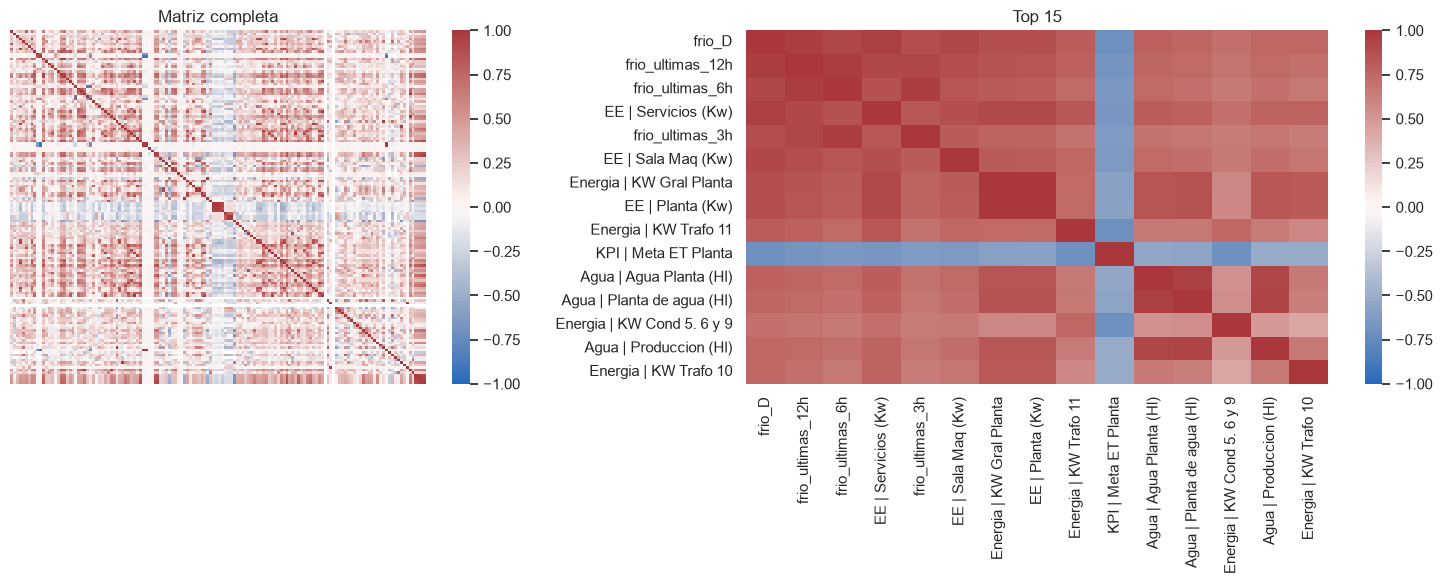

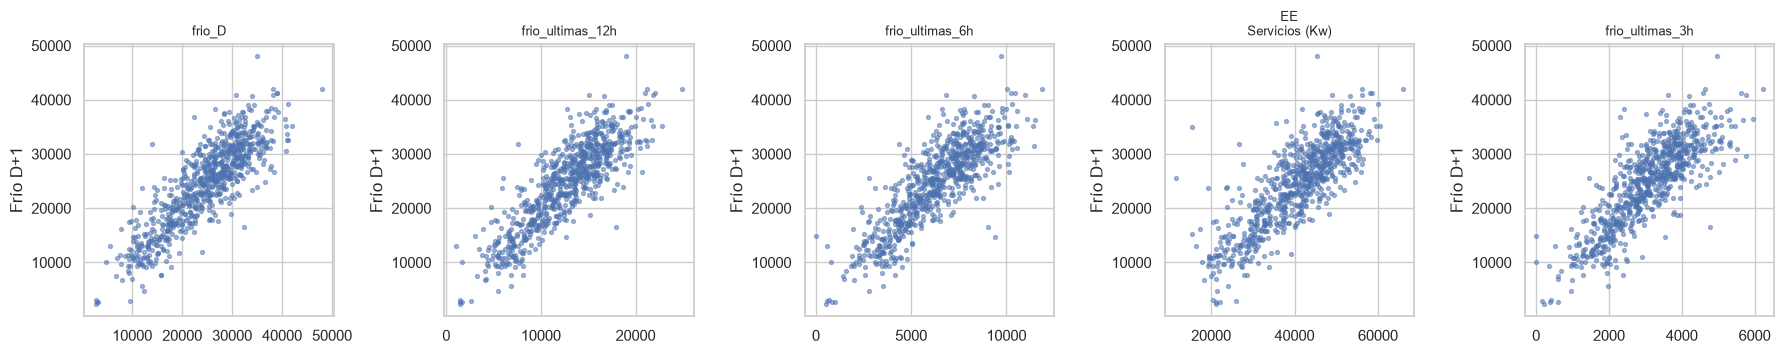

In [67]:
corr0=af.correlaciones(P,y,'D crudo');corrD=af.correlaciones(Q.drop(columns='frio_D'),y,'D depurado');corr=af.correlaciones(Q,target,'D+1')
print('Correlaciones individuales |Pearson| > .98 con Frío D:',int(corrD.pearson.abs().gt(.98).sum()))
display(corr.head(15).round(4))
comparacion=pd.concat([corr0.set_index('variable').pearson.rename('crudo'),corrD.set_index('variable').pearson.rename('depurado'),corrD.set_index('variable').spearman.rename('Spearman')],axis=1)
display(comparacion.loc[comparacion.index.str.contains('Sala Maq|Envasado',regex=True)].head(10).round(4))
M=Q.corr(min_periods=30);pares=[(a,b,M.loc[a,b]) for a,b in combinations(M.columns,2) if abs(M.loc[a,b])>=.95]
print('Pares redundantes:',len(pares));display(pd.DataFrame(pares,columns=['variable 1','variable 2','Pearson']).sort_values('Pearson',key=abs,ascending=False).head(10))
fig,ax=plt.subplots(1,2,figsize=(15,6),gridspec_kw={'width_ratios':[1,1.4]});sns.heatmap(M,vmin=-1,vmax=1,center=0,cmap='vlag',xticklabels=False,yticklabels=False,ax=ax[0]);ax[0].set_title('Matriz completa');top=corr.variable.head(15).tolist();sns.heatmap(M.loc[top,top],vmin=-1,vmax=1,center=0,cmap='vlag',ax=ax[1]);ax[1].set_title('Top 15');plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,5,figsize=(18,3.7))
for a,c in zip(axs,top[:5]):
    a.scatter(Q[c],target,s=8,alpha=.5);a.set_title(c.replace(' | ','\n'),fontsize=9);a.set_ylabel('Frío D+1')
plt.tight_layout();plt.show()

Los extremos pueden ocultar asociaciones importantes. Los pares con |r|≥0,95 indican redundancia; no implican descartar automáticamente una variable. La selección se ajustará dentro de cada fold, considerando cobertura, sentido físico y aporte predictivo.

## 9. Ventanas intradiarias
Calculamos el cierre de 23:59 menos la lectura de 21:00, 18:00 y 12:00. La correlación parcial controla Frío de D y el mes para estudiar si queda información adicional.

In [68]:
vent=[]
for k in (3,6,12):
    t=pd.DataFrame({'x':Q[f'frio_ultimas_{k}h'],'y':target,'frio_D':y}).dropna()
    z=np.column_stack([np.ones(len(t)),t.frio_D,pd.get_dummies(t.index.month,drop_first=True,dtype=float)])
    rx=t.x-z@np.linalg.lstsq(z,t.x,rcond=None)[0];ry=t.y-z@np.linalg.lstsq(z,t.y,rcond=None)[0]
    vent.append((k,len(t),t.x.corr(t.y),rx.corr(ry)))
display(pd.DataFrame(vent,columns=['horas','n','Pearson D+1','correlación parcial']).round(4))

,horas,n,Pearson D+1,correlación parcial
0,3,752,0.8196,0.2765
1,6,752,0.8386,0.2671
2,12,752,0.8550,0.2242


## Conclusiones
| Evidencia | Decisión candidata |
|---|---|
| Bloques apilados y secuencias alineadas | Reconstrucción relativa; verificar anclas absolutas y excepción de 2023 |
| Cierre ausente y saltos | Priorizar observaciones coherentes; evaluar extrapolación o reparación solo para predictores |
| Faltantes estructurales y alias Vapor L5 | Normalizar esquemas; evaluar imputación histórica y KNN en CV |
| Señal semanal débil y cambio interanual | Evaluar lag 7, calendario y medias causales de 14/30 días |
| Balance de 12 medidores y redundancia | Evitar agregados duplicados; evaluar filtro de correlación y regularización |
| Correlaciones parciales positivas | Evaluar ventanas de 3, 6 y 12 h |

No se entrena ningún modelo ni se modifica el dataset final. Los parámetros se ajustarán dentro de cada fold. El Test histórico ya fue utilizado y no es una evaluación independiente de la nueva versión. Los gráficos y resultados quedan en las salidas del notebook; no se crean carpetas en `results/`.